# 02 — EDA of the original LendingClub accepted-loans file

Source: Kaggle [All Lending Club loan data](https://www.kaggle.com/datasets/wordsforthewise/lending-club), `accepted_2007_to_2018Q4.csv` (2.26M loans × 151 columns, snapshot as of 2018 Q4).

Column descriptions and groups come from `data_dictionary.csv`, built by `scripts/build_data_dictionary.py` from LendingClub's official `LCDataDictionary.xlsx`. A column counts as known at origination if it is listed in the dictionary's *browseNotes* sheet, i.e. it was shown to investors before the loan was funded.

Goals:
1. Confirm how `LC_loans_granting_model_dataset.csv` (notebook 01) was derived from this file.
2. Separate leakage, lender-decision and usable application-time columns.
3. Measure how much signal the ~99 application-time columns add over the 15-column subset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import yaml
from sklearn.metrics import roc_auc_score

from loan_approval.data.clean import replace_suspicious_values

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
cfg = yaml.safe_load((ROOT / 'configs/config.yaml').read_text())
RAW = ROOT / cfg['paths']['raw_data']
ORIG_PATH = RAW / cfg['data']['original_file']
FILT_PATH = RAW / cfg['data']['raw_file']
TARGET = cfg['data']['target']

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.max_colwidth', 90)

dd = pd.read_csv(ROOT / cfg['data']['data_dictionary'])

# Lazy scan, all columns as strings: cheap whole-file statistics without loading 1.7 GB into memory
lf_all = pl.scan_csv(ORIG_PATH, infer_schema=False)
lf = lf_all.filter(pl.col('loan_amnt').is_not_null())  # drops summary/footer rows


def month_to_date(col: str) -> pl.Expr:
    return pl.concat_str(pl.lit('01-'), pl.col(col)).str.to_date('%d-%b-%Y')


# Resolved outcome: Fully Paid -> 0, Charged Off -> 1 (incl. 'Does not meet the credit policy' variants)
OUTCOME = (pl.when(pl.col('loan_status').str.ends_with('Charged Off')).then(1)
           .when(pl.col('loan_status').str.ends_with('Fully Paid')).then(0)
           .otherwise(None).alias(TARGET))

## 1. Overview

In [2]:
lf_all.select(
    pl.len().alias('rows_in_file'),
    pl.col('loan_amnt').is_null().sum().alias('footer_rows'),
).collect(engine='streaming')

rows_in_file,footer_rows
u32,u32
2260701,33


In [3]:
print('Footer rows look like:', lf_all.filter(pl.col('loan_amnt').is_null()).select('id')
      .collect()['id'].head(2).to_list())
print('Columns:', len(lf.collect_schema()))
lf.select(
    pl.len().alias('loans'),
    pl.col('id').n_unique().alias('unique_ids'),
    pl.col('member_id').is_not_null().sum().alias('member_id_non_null'),
).collect(engine='streaming')

Footer rows look like: ['Total amount funded in policy code 1: 6417608175', 'Total amount funded in policy code 2: 1944088810']
Columns: 151


loans,unique_ids,member_id_non_null
u32,u32,u32
2260668,2260668,0


In [4]:
# Column groups from data_dictionary.csv
dd.groupby('group').agg(n_columns=('column', 'size'),
                        shown_at_listing=('shown_at_listing', 'sum'),
                        examples=('column', lambda s: ', '.join(s.head(6))))

,n_columns,shown_at_listing,examples
group,,,
application,99,98,"loan_amnt, term, emp_title, emp_length, home_ownership, annual_inc"
identifier,3,3,"id, member_id, url"
lender_decision,9,7,"funded_amnt, funded_amnt_inv, int_rate, installment, grade, sub_grade"
origination_meta,1,0,issue_d
post_origination_leakage,38,0,"pymnt_plan, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp"
target_source,1,0,loan_status


## 2. `loan_status` and the snapshot bias

In [5]:
status = (lf.select('loan_status', 'issue_d', 'term')
          .with_columns(OUTCOME,
                        year=month_to_date('issue_d').dt.year(),
                        term=pl.col('term').str.strip_chars())
          .collect(engine='streaming')
          .to_pandas())
status['loan_status'].value_counts().to_frame().assign(share=lambda t: t['count'] / t['count'].sum())

,count,share
loan_status,,
Fully Paid,1076751,0.476
Current,878317,0.389
Charged Off,268559,0.119
Late (31-120 days),21467,0.009
In Grace Period,8436,0.004
Late (16-30 days),4349,0.002
Does not meet the credit policy. Status:Fully Paid,1988,0.001
Does not meet the credit policy. Status:Charged Off,761,0.000
Default,40,0.000


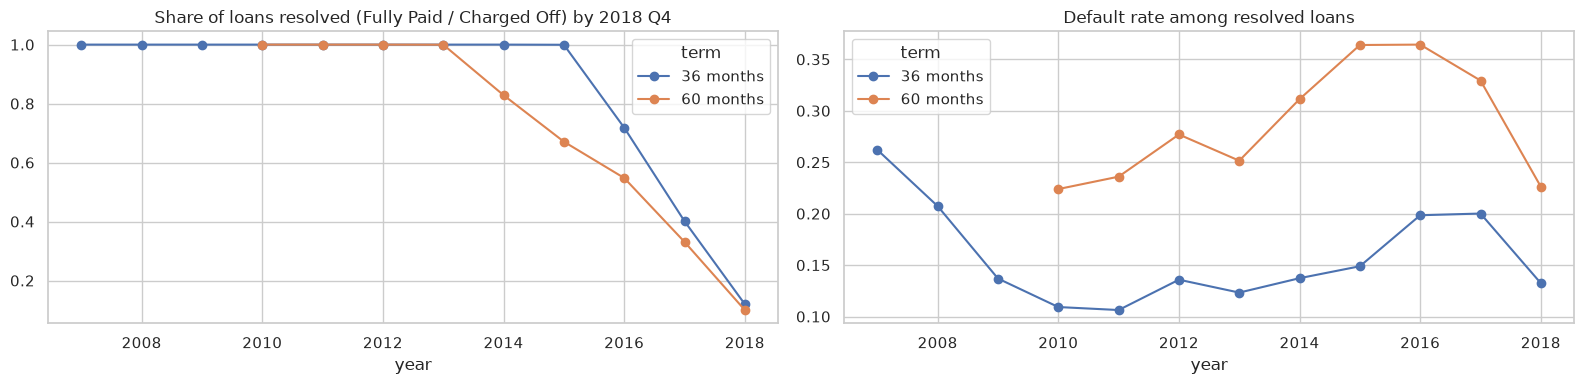

loans             resolved_share           default_rate          
term   36 months   60 months      36 months 60 months    36 months 60 months
year                                                                        
2007     603.000         NaN          1.000       NaN        0.262       NaN
2008   2,393.000         NaN          1.000       NaN        0.207       NaN
2009   5,281.000         NaN          1.000       NaN        0.137       NaN
2010   9,156.000   3,381.000          1.000     1.000        0.109     0.224
2011  14,101.000   7,620.000          1.000     1.000        0.106     0.236
2012  43,470.000   9,897.000          1.000     1.000        0.136     0.277
2013 100,422.000  34,392.000          1.000     1.000        0.123     0.251
2014 162,570.000  73,059.000          1.000     0.829        0.137     0.311
2015 283,173.000 137,922.000          0.999     0.671        0.149     0.364
2016 323,495.000 110,912.000          0.718     0.548        0.198     0.364
2017 320,419.000 123,160.000          0.401     0.331        0.200     0.329
2018 344,671.000 150,571.000          0.120     0.100        0.132     0.226

In [6]:
status['resolved'] = status[TARGET].notna()
by_year_term = status.groupby(['year', 'term']).agg(
    loans=('resolved', 'size'), resolved_share=('resolved', 'mean'), default_rate=(TARGET, 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
by_year_term['resolved_share'].unstack().plot(marker='o', ax=axes[0])
axes[0].set_title('Share of loans resolved (Fully Paid / Charged Off) by 2018 Q4')
by_year_term['default_rate'].unstack().plot(marker='o', ax=axes[1])
axes[1].set_title('Default rate among resolved loans')
plt.tight_layout(); plt.show()
by_year_term.unstack()

## 3. Reproducing the 15-column filtered dataset

In [7]:
orig_keys = (lf.select('id', 'loan_status', 'issue_d', 'application_type', 'annual_inc', 'annual_inc_joint',
                       'dti', 'dti_joint', 'fico_range_low', 'fico_range_high', 'emp_length',
                       'home_ownership')
               .with_columns(OUTCOME).collect(engine='streaming'))
filt = pl.read_csv(FILT_PATH, infer_schema=False).select(
    'id', 'Default', 'revenue', 'dti_n', 'fico_n', 'emp_length', 'home_ownership_n', 'experience_c')
j = filt.join(orig_keys, on='id', how='left', suffix='_orig')
f = lambda c: pl.col(c).cast(pl.Float64)
is_joint = pl.col('application_type') == 'Joint App'
checks = j.select(
    pl.len().alias('filtered_rows'),
    pl.col('loan_status').is_not_null().sum().alias('ids_found_in_original'),
    (pl.col('Default').cast(pl.Int32) == pl.col(f'{TARGET}_orig')).mean().alias('Default_matches_loan_status'),
    (f('fico_n') == (f('fico_range_low') + f('fico_range_high')) / 2).mean().alias('fico_n == mean(fico_range)'),
    (f('revenue') == pl.when(is_joint).then(f('annual_inc_joint')).otherwise(f('annual_inc')))
        .mean().alias('revenue == annual_inc (joint: annual_inc_joint)'),
    (f('dti_n') == pl.when(is_joint).then(pl.max_horizontal(f('dti'), f('dti_joint'))).otherwise(f('dti')))
        .mean().alias('dti_n == dti (joint: max(dti, dti_joint))'),
    ((pl.col('emp_length') == 'NI') == pl.col('emp_length_orig').is_null()).mean().alias('NI == missing emp_length'),
)
checks.to_pandas().T.rename(columns={0: 'value'})

,value
filtered_rows,"1,347,681.000"
ids_found_in_original,"1,347,681.000"
Default_matches_loan_status,1.000
fico_n == mean(fico_range),1.000
revenue == annual_inc (joint: annual_inc_joint),1.000
"dti_n == dti (joint: max(dti, dti_joint))",1.000
NI == missing emp_length,1.000


In [8]:
j.group_by('loan_status', 'Default').len().sort('loan_status').to_pandas()

,loan_status,Default,len
0,Charged Off,1,268488
1,Does not meet the credit policy. Status:Charged Off,1,761
2,Does not meet the credit policy. Status:Fully Paid,0,1984
3,Fully Paid,0,1076448


In [9]:
j.group_by('home_ownership_n', 'home_ownership').len().sort('home_ownership_n').to_pandas()

,home_ownership_n,home_ownership,len
0,MORTGAGE,MORTGAGE,666594
1,OTHER,OTHER,182
2,OTHER,ANY,286
3,OTHER,NONE,49
4,OWN,OWN,144985
5,RENT,RENT,535585


In [10]:
# Resolved loans in the original that are NOT in the filtered file
dropped = (orig_keys.filter(pl.col(TARGET).is_not_null() | (pl.col('loan_status') == 'Default'))
                    .join(filt.select('id'), on='id', how='anti'))
print('dropped resolved loans:', dropped.height)
dropped.with_columns(
    income_or_dti_missing=pl.when(pl.col('application_type') == 'Joint App')
        .then(pl.col('annual_inc_joint').is_null() | pl.col('dti_joint').is_null() | pl.col('dti').is_null())
        .otherwise(pl.col('annual_inc').is_null() | pl.col('dti').is_null())
).group_by('loan_status', 'application_type', 'income_or_dti_missing').len().sort('len', descending=True).to_pandas()

dropped resolved loans: 418


,loan_status,application_type,income_or_dti_missing,len
0,Fully Paid,Joint App,True,303
1,Charged Off,Joint App,True,71
2,Default,Individual,False,34
3,Default,Joint App,False,6
4,Does not meet the credit policy. Status:Fully Paid,Individual,True,4


In [11]:
# experience_c: not an original column - where are its 25 zeros?
exp0 = j.filter(pl.col('experience_c') == '0')
print(exp0['issue_d'].value_counts().sort('issue_d').to_pandas().to_string(index=False))
earliest = orig_keys.with_columns(d=month_to_date('issue_d')).filter(pl.col('d') <= pl.date(2007, 8, 1))
print('loans issued Jun-Aug 2007 in the original:', earliest.height)

 issue_d  count
Aug-2007      2
Jul-2007      3
Jun-2007     20
loans issued Jun-Aug 2007 in the original: 161


## 4. Load the modelling frame (resolved loans, typed columns)

In [12]:
APP = dd.loc[dd['group'] == 'application', 'column'].tolist()
TEXT = ['term', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'desc', 'purpose',
        'title', 'zip_code', 'addr_state', 'earliest_cr_line', 'application_type',
        'verification_status_joint', 'sec_app_earliest_cr_line']
LENDER = ['grade', 'sub_grade', 'int_rate', 'installment', 'funded_amnt']
LEAK_DEMO = ['recoveries', 'collection_recovery_fee', 'total_rec_prncp', 'total_pymnt', 'last_pymnt_amnt',
             'last_fico_range_high', 'out_prncp', 'debt_settlement_flag', 'hardship_flag']
STR_EXTRA = ['grade', 'sub_grade', 'debt_settlement_flag', 'hardship_flag']
cols = list(dict.fromkeys(['id', 'issue_d', 'loan_status'] + APP + LENDER + LEAK_DEMO))
NUM = [c for c in cols if c not in TEXT + STR_EXTRA + ['id', 'issue_d', 'loan_status']]

df = (lf.select(cols)
        .with_columns(OUTCOME)
        .filter(pl.col(TARGET).is_not_null())
        .with_columns([pl.col(c).cast(pl.Float64) for c in NUM])
        .with_columns(issue_date=month_to_date('issue_d'),
                      term_months=pl.col('term').str.extract(r'(\d+)').cast(pl.Float64))
        .with_columns(year=pl.col('issue_date').dt.year(),
                      credit_history_months=(pl.col('issue_date') - month_to_date('earliest_cr_line'))
                          .dt.total_days() / 30.44)
        .collect(engine='streaming')
        .to_pandas())
before = df[NUM].isna().sum()
df = replace_suspicious_values(df)  # placeholder codes (dti -1/999, 999 months, 9,999,999 limit) -> NaN
print('Values set to NaN:', (df[NUM].isna().sum() - before).loc[lambda s: s > 0].to_dict())
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df[TARGET].value_counts(normalize=True)

Values set to NaN: {'dti': 40, 'revol_util': 1, 'total_rev_hi_lim': 3, 'mo_sin_old_il_acct': 1}
(1348059, 121) 1.51 GB


Default
0   0.800
1   0.200
Name: proportion, dtype: float64

## 5. Column classification with missingness

In [13]:
miss = (df[[c for c in dd['column'] if c in df]].isna().mean() * 100).rename('missing_pct_resolved')
table = dd.merge(miss, left_on='column', right_index=True, how='left')
table.groupby('group')['missing_pct_resolved'].describe()[['count', 'min', '50%', 'max']]

,count,min,50%,max
group,,,,
application,99.000,0.000,5.213,99.507
identifier,1.000,0.000,0.000,0.000
lender_decision,5.000,0.000,0.000,0.000
origination_meta,1.000,0.000,0.000,0.000
post_origination_leakage,9.000,0.000,0.000,0.000
target_source,1.000,0.000,0.000,0.000


In [14]:
table.loc[table['group'] == 'application',
          ['column', 'description', 'missing_pct_resolved', 'filtered_dataset_column']] \
     .sort_values('missing_pct_resolved').reset_index(drop=True)

,column,description,missing_pct_resolved,filtered_dataset_column
0,loan_amnt,"The listed amount of the loan applied for by the borrower. If at some point in time, t...",0.000,loan_amnt
1,term,The number of payments on the loan. Values are in months and can be either 36 or 60.,0.000,NaN
2,verification_status,"Indicates if income was verified by LC, not verified, or if the income source was veri...",0.000,NaN
3,home_ownership,The home ownership status provided by the borrower during registration or obtained fro...,0.000,home_ownership_n
4,addr_state,The state provided by the borrower in the loan application,0.000,addr_state
...,...,...,...,...
94,sec_app_collections_12_mths_ex_med,Number of collections within last 12 months excluding medical collections at time of a...,98.618,NaN
95,sec_app_chargeoff_within_12_mths,Number of charge-offs within last 12 months at time of application for the secondary a...,98.618,NaN
96,revol_bal_joint,"Sum of revolving credit balance of the co-borrowers, net of duplicate balances",98.618,NaN
97,sec_app_revol_util,Ratio of total current balance to high credit/credit limit for all revolving accounts,98.642,NaN


## 6. Leakage demonstration: single-feature ROC-AUC

AUC is direction-free here: `max(AUC, 1 − AUC)`, computed on non-missing rows. Application-time credit features typically score 0.50–0.65 alone; post-origination columns score far higher.

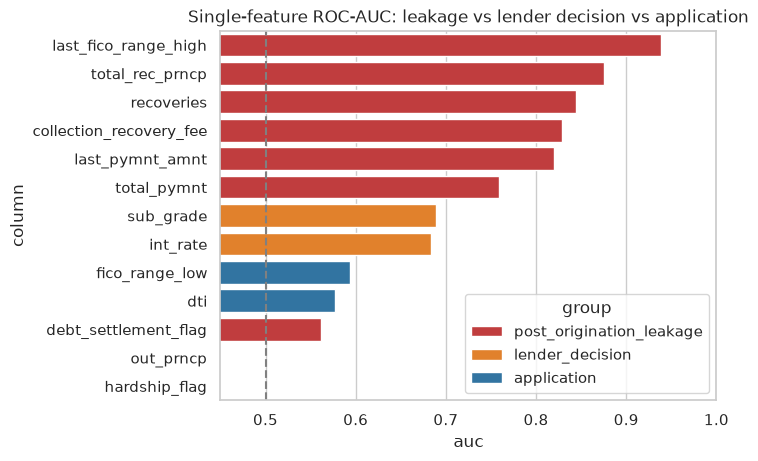

,column,group,auc,coverage
5,last_fico_range_high,post_origination_leakage,0.939,1.000
2,total_rec_prncp,post_origination_leakage,0.875,1.000
0,recoveries,post_origination_leakage,0.844,1.000
1,collection_recovery_fee,post_origination_leakage,0.829,1.000
4,last_pymnt_amnt,post_origination_leakage,0.820,1.000
3,total_pymnt,post_origination_leakage,0.759,1.000
10,sub_grade,lender_decision,0.689,1.000
9,int_rate,lender_decision,0.683,1.000
11,fico_range_low,application,0.593,1.000
12,dti,application,0.577,1.000


In [15]:
y = df[TARGET].to_numpy()


def single_auc(s: pd.Series) -> tuple[float, float]:
    m = s.notna().to_numpy()
    if m.sum() < 1000 or s[m].nunique() < 2 or len(np.unique(y[m])) < 2:
        return np.nan, m.mean()
    a = roc_auc_score(y[m], s[m])
    return max(a, 1 - a), m.mean()


SUB_GRADE_RANK = {g: i for i, g in enumerate(sorted(df['sub_grade'].dropna().unique()))}
demo = {
    **{c: df[c] for c in LEAK_DEMO if c in NUM},
    'debt_settlement_flag': (df['debt_settlement_flag'] == 'Y').astype(float),
    'hardship_flag': (df['hardship_flag'] == 'Y').astype(float),
    'int_rate': df['int_rate'],
    'sub_grade': df['sub_grade'].map(SUB_GRADE_RANK),
    'fico_range_low': df['fico_range_low'],
    'dti': df['dti'],
}
group_of = dict(zip(dd['column'], dd['group']))
leak_auc = pd.DataFrame([(c, group_of[c], *single_auc(s)) for c, s in demo.items()],
                        columns=['column', 'group', 'auc', 'coverage']).sort_values('auc', ascending=False)
palette = {'post_origination_leakage': 'tab:red', 'lender_decision': 'tab:orange', 'application': 'tab:blue'}
ax = sns.barplot(data=leak_auc, y='column', x='auc', hue='group', palette=palette, dodge=False)
ax.axvline(0.5, color='grey', ls='--'); ax.set_xlim(0.45, 1.0)
ax.set_title('Single-feature ROC-AUC: leakage vs lender decision vs application'); plt.show()
leak_auc

## 7. Signal in the application-time features

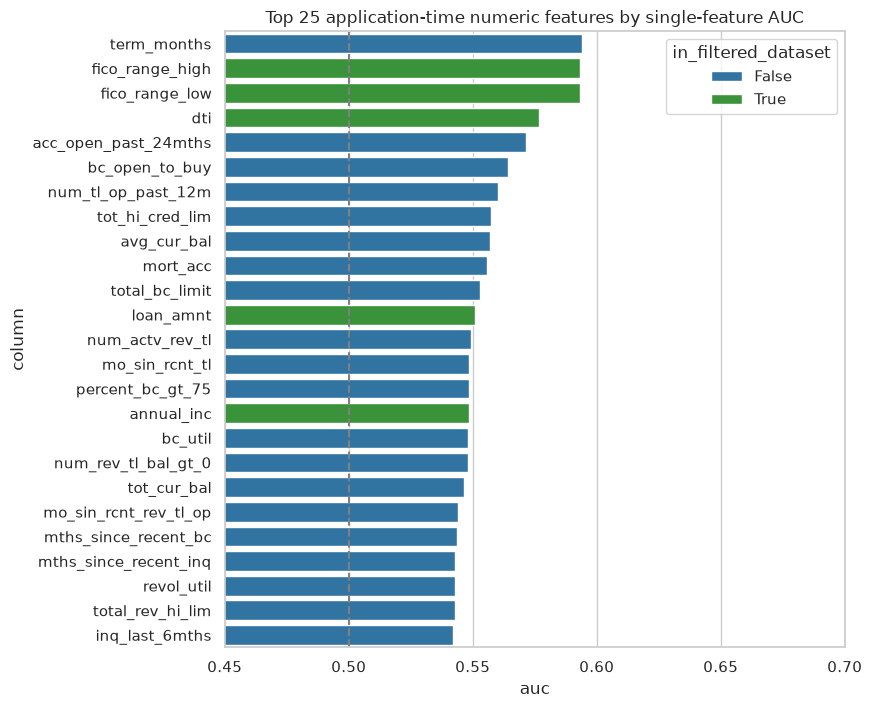

,column,auc,coverage,in_filtered_dataset
0,term_months,0.594,1.000,False
1,fico_range_high,0.593,1.000,True
2,fico_range_low,0.593,1.000,True
3,dti,0.577,1.000,True
4,acc_open_past_24mths,0.571,0.963,False
5,bc_open_to_buy,0.564,0.953,False
6,num_tl_op_past_12m,0.560,0.948,False
7,tot_hi_cred_lim,0.557,0.948,False
8,avg_cur_bal,0.557,0.948,False
9,mort_acc,0.556,0.963,False


In [16]:
num_app = [c for c in APP if c in NUM] + ['term_months', 'credit_history_months']
app_auc = pd.DataFrame([(c, *single_auc(df[c])) for c in num_app], columns=['column', 'auc', 'coverage'])
app_auc['in_filtered_dataset'] = app_auc['column'].map(
    dict(zip(dd['column'], dd['filtered_dataset_column'].notna())) | {'term_months': False, 'credit_history_months': False})
app_auc = app_auc.sort_values('auc', ascending=False).reset_index(drop=True)
# Rank only features present for at least half the loans; sec_app_* / joint fields cover <2%
app_auc = app_auc[app_auc['coverage'] >= 0.5].reset_index(drop=True)
top = app_auc.head(25)
plt.figure(figsize=(8, 8))
ax = sns.barplot(data=top, y='column', x='auc', hue='in_filtered_dataset', dodge=False,
                 palette={True: 'tab:green', False: 'tab:blue'})
ax.axvline(0.5, color='grey', ls='--'); ax.set_xlim(0.45, 0.7)
ax.set_title('Top 25 application-time numeric features by single-feature AUC'); plt.show()
app_auc.head(30)

In [17]:
# Missingness as signal: default rate when a feature is missing vs present (features with >=5% missing)
rows = []
for c in APP:
    m = df[c].isna()
    if 0.05 <= m.mean() <= 0.95:
        rows.append((c, m.mean(), df.loc[m, TARGET].mean(), df.loc[~m, TARGET].mean()))
miss_signal = pd.DataFrame(rows, columns=['column', 'missing_share', 'default_if_missing', 'default_if_present'])
miss_signal['gap'] = miss_signal['default_if_missing'] - miss_signal['default_if_present']
miss_signal.reindex(miss_signal['gap'].abs().sort_values(ascending=False).index).head(15)

,column,missing_share,default_if_missing,default_if_present,gap
1,emp_length,0.058,0.269,0.195,0.074
0,emp_title,0.064,0.262,0.196,0.066
29,mths_since_recent_inq,0.131,0.151,0.207,-0.056
2,desc,0.907,0.204,0.156,0.049
43,pct_tl_nvr_dlq,0.052,0.158,0.202,-0.044
19,total_rev_hi_lim,0.052,0.158,0.202,-0.044
37,num_rev_accts,0.052,0.158,0.202,-0.044
27,mo_sin_rcnt_tl,0.052,0.158,0.202,-0.044
41,num_tl_90g_dpd_24m,0.052,0.158,0.202,-0.044
40,num_tl_30dpd,0.052,0.158,0.202,-0.044


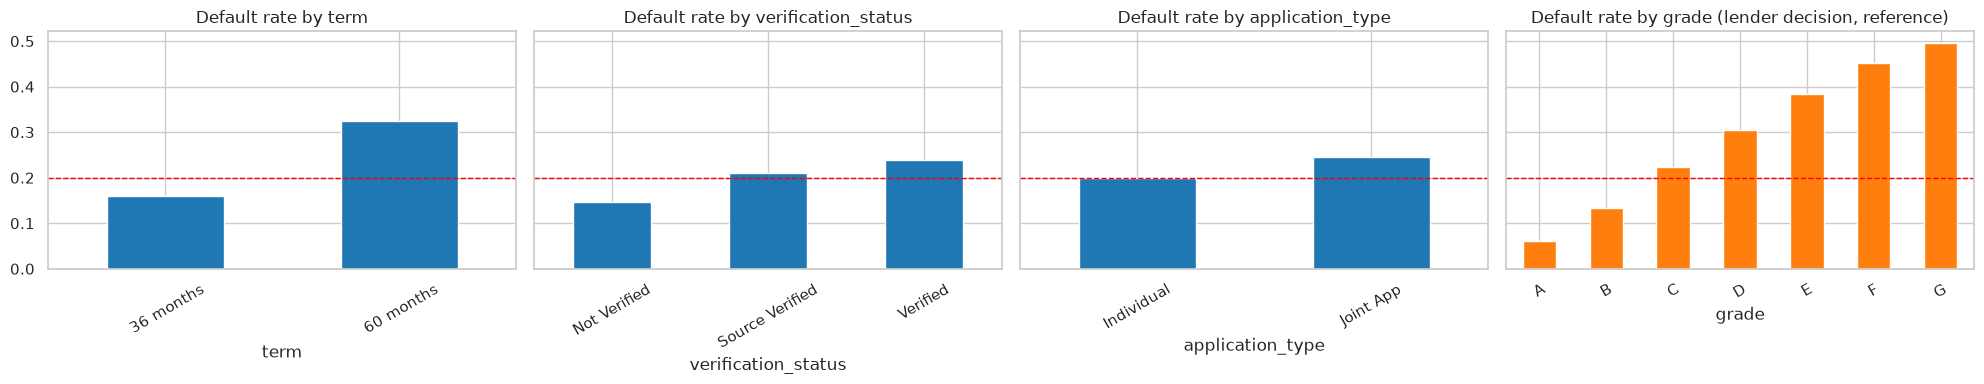

,n,default_rate
term,,
36 months,1023181,0.160
60 months,324878,0.324


,n,default_rate
verification_status,,
Not Verified,407533,0.147
Source Verified,521563,0.210
Verified,418963,0.239


,n,default_rate
application_type,,
Individual,1322259,0.199
Joint App,25800,0.246


,n,default_rate
grade,,
A,235188,0.060
B,393095,0.134
C,382315,0.224
D,201644,0.304
E,94186,0.384
F,32305,0.451
G,9326,0.497


In [18]:
def default_rate(col: str) -> pd.DataFrame:
    return (df.groupby(col)[TARGET].agg(n='size', default_rate='mean')
              .sort_values('default_rate'))


fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, col in zip(axes, ['term', 'verification_status', 'application_type', 'grade']):
    default_rate(col)['default_rate'].plot.bar(ax=ax, color='tab:orange' if col == 'grade' else 'tab:blue')
    ax.axhline(df[TARGET].mean(), color='red', ls='--', lw=1)
    ax.set_title(f'Default rate by {col}' + (' (lender decision, reference)' if col == 'grade' else ''))
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
for col in ['term', 'verification_status', 'application_type', 'grade']:
    display(default_rate(col))

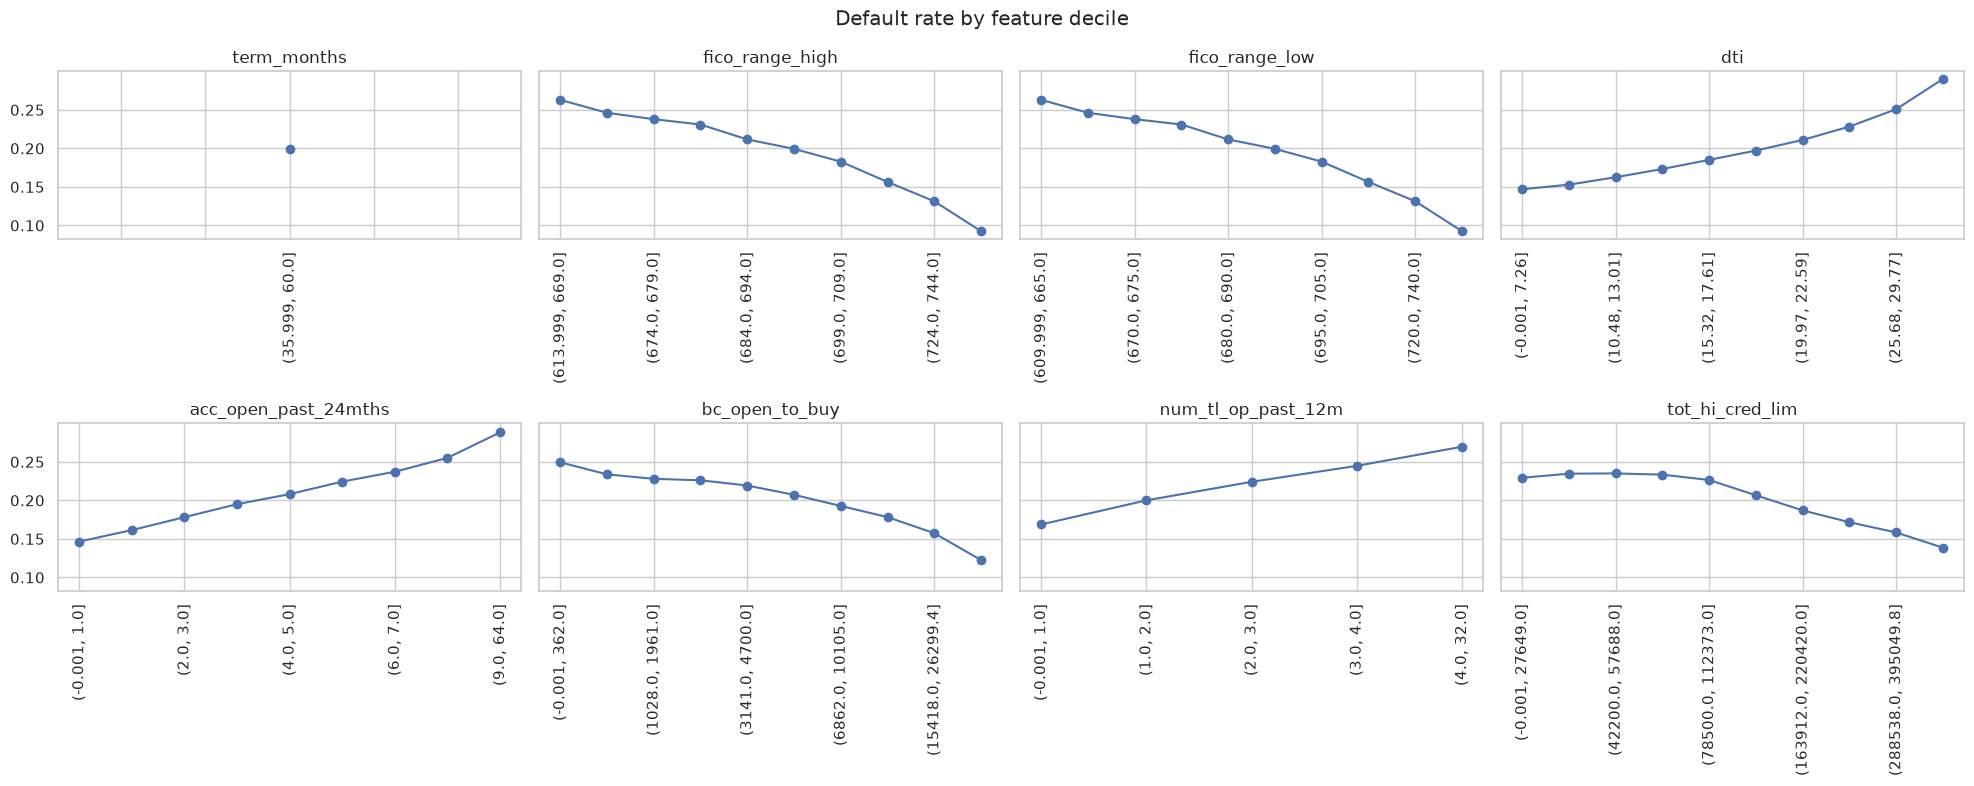

In [19]:
# Default rate by decile for the top 8 features
top8 = app_auc['column'].head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=True)
for ax, col in zip(axes.flat, top8):
    bins = pd.qcut(df[col], 10, duplicates='drop')
    df.groupby(bins, observed=True)[TARGET].mean().plot(marker='o', ax=ax)
    ax.set_title(col); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=90)
plt.suptitle('Default rate by feature decile'); plt.tight_layout(); plt.show()

## 8. Feature availability over time

Many bureau fields were added to LendingClub's data later. Missing % by issue year, shown for application features that are >5% missing in at least one year.

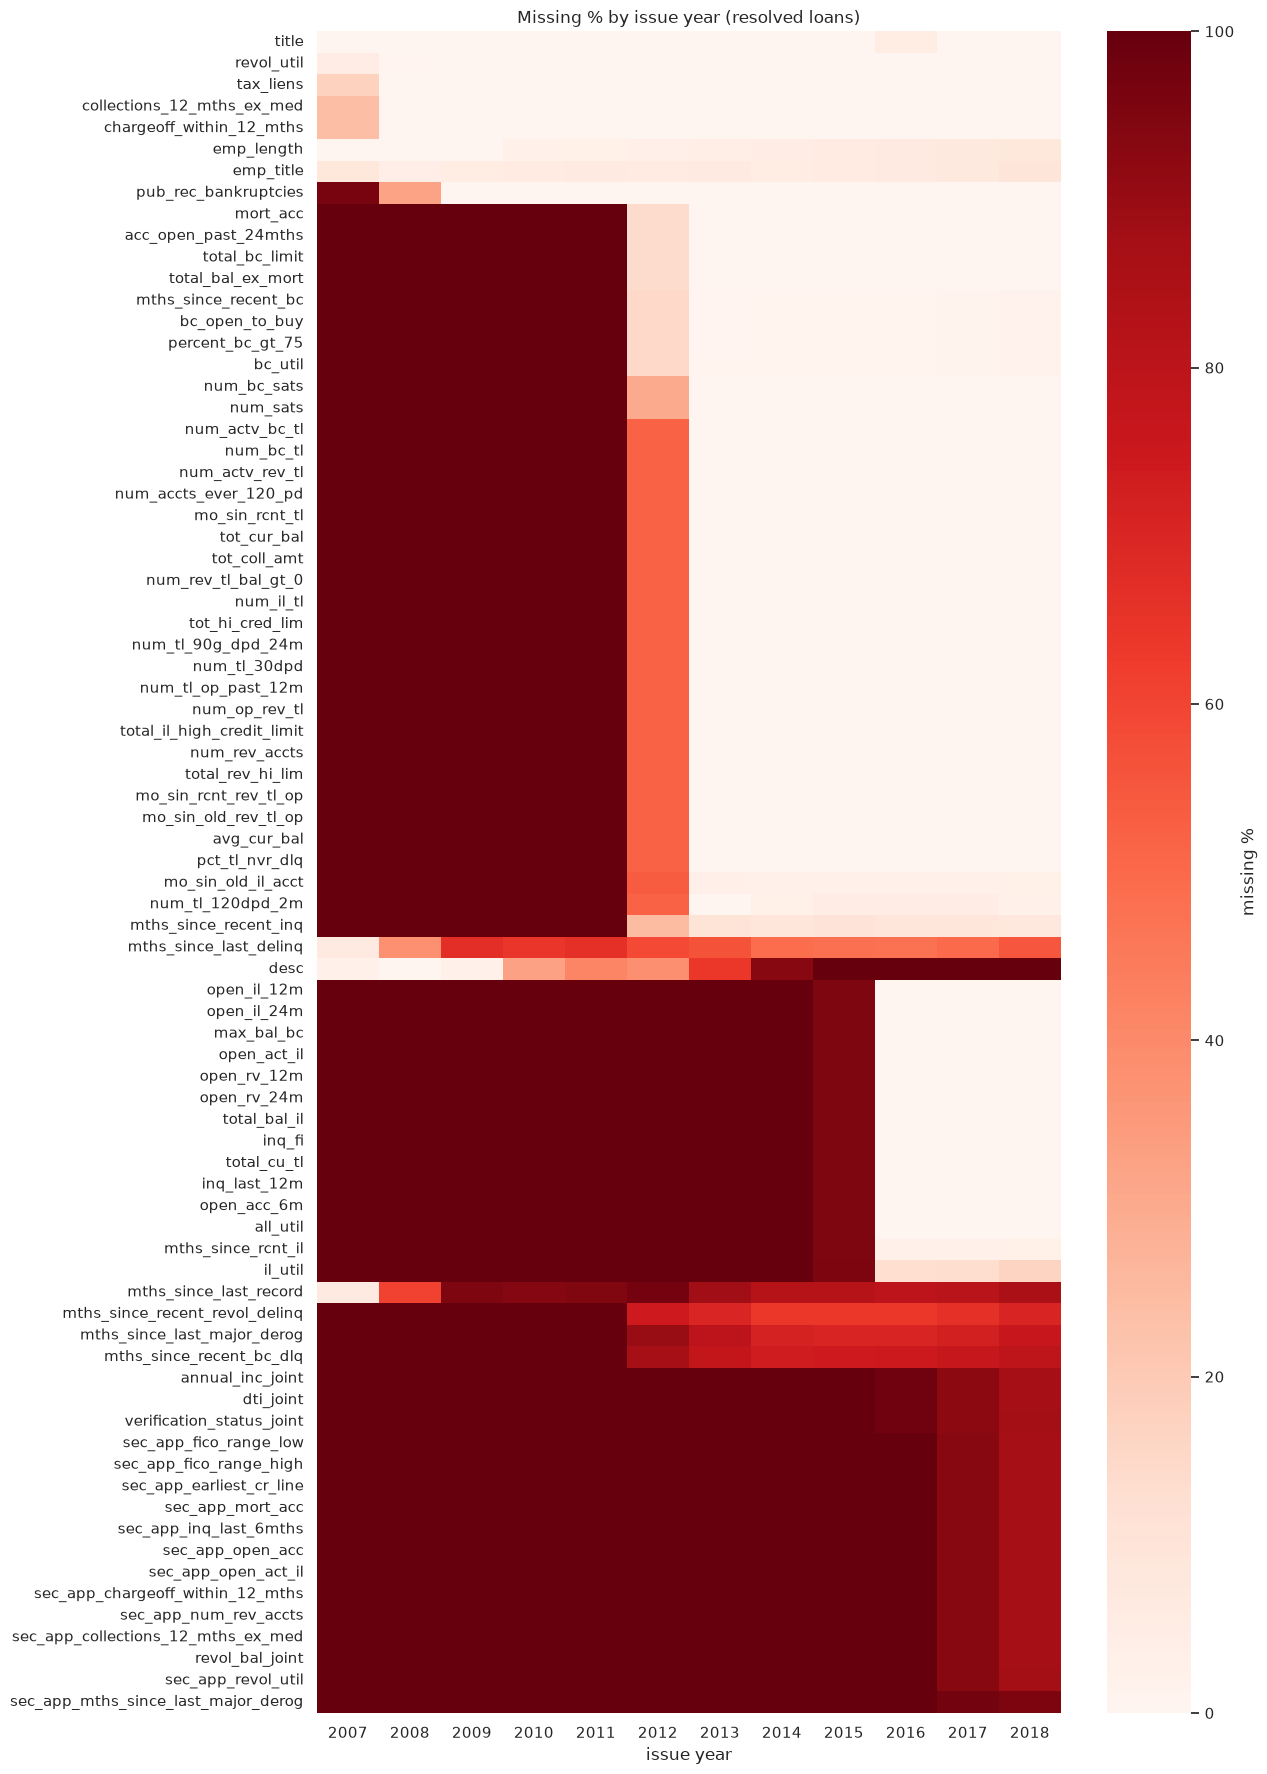

Application features complete (<5% missing) in every year: 21 of 99


In [20]:
avail = df.groupby('year')[APP].apply(lambda g: g.isna().mean() * 100).T
avail = avail[avail.max(axis=1) > 5]
avail = avail.loc[avail.mean(axis=1).sort_values().index]
plt.figure(figsize=(12, max(6, 0.28 * len(avail))))
sns.heatmap(avail, cmap='Reds', vmin=0, vmax=100, cbar_kws={'label': 'missing %'})
plt.title('Missing % by issue year (resolved loans)'); plt.xlabel('issue year'); plt.show()
print('Application features complete (<5% missing) in every year:',
      len(APP) - len(avail), 'of', len(APP))

In [21]:
# First issue year in which each partially-available feature is >= 95% populated
ok = avail < 5
first_year = ok.idxmax(axis=1).where(ok.any(axis=1)).astype('Int64')
display(first_year.value_counts(dropna=False).sort_index().rename('n_features_fully_available_from'))
first_year.groupby(first_year).apply(lambda s: ', '.join(s.index[:8]))

2007     3
2008     5
2009     1
2013    33
2016    13
<NA>    23
Name: n_features_fully_available_from, dtype: Int64

2007                                                                      title, emp_length, desc
2008       revol_util, tax_liens, collections_12_mths_ex_med, chargeoff_within_12_mths, emp_title
2009                                                                         pub_rec_bankruptcies
2013    mort_acc, acc_open_past_24mths, total_bc_limit, total_bal_ex_mort, mths_since_recent_b...
2016    open_il_12m, open_il_24m, max_bal_bc, open_act_il, open_rv_12m, open_rv_24m, total_bal...
dtype: str

## 9. Key findings

**File structure**
- 2,260,701 rows, of which 33 are footer rows ("Total amount funded in policy code …"). That leaves **2,260,668 loans × 151 columns**, with `id` unique. `member_id` is empty in every row, so borrowers can't be linked across loans.
- `data_dictionary.csv` groups the 151 columns: **99 application**, 38 post-origination leakage, 9 lender decision, 3 identifiers, `issue_d`, and `loan_status`.

**How the 15-column file was built** (every check matches 100%)
- Rows: loans with status Fully Paid / Charged Off, including the "Does not meet the credit policy" variants. The 40 `Default`-status loans are excluded, and so are 378 loans with missing income or DTI (374 of them joint applications).
- `Default` = 1 for Charged Off, 0 for Fully Paid. `fico_n` = mean of `fico_range_low` and `fico_range_high`.
- `revenue` = `annual_inc`, or `annual_inc_joint` for joint applications. `dti_n` = `dti`, or **max(`dti`, `dti_joint`)** for joint applications.
- `emp_length` "NI" = missing. `home_ownership` values ANY/NONE/OTHER are grouped as OTHER.
- `experience_c` = 0 only for 25 loans issued Jun–Aug 2007, LendingClub's first months (161 loans issued then). It's effectively constant, so drop it.

**Snapshot bias (now quantified)**
- By 2018 Q4, only 40% of 2017 loans and 12% of 2018 loans had resolved. For 60-month loans, resolution is already incomplete from 2014 (83%).
- Default rate among resolved loans by issue year:
  - 36-month: 11–15% for 2010–2015, rising to 20% for 2016–17, then down to 13% for 2018;
  - 60-month: 22–36%.
- The 2016–2018 rates come from early-resolving loans, not a representative sample. **Recommended:** train only on vintages that have fully resolved (36-month loans issued ≤ 2015; 60-month loans issued ≤ 2013), or at least split by time.

**Leakage**
- Post-origination columns have single-feature AUC 0.76–0.94: `last_fico_range_high` 0.94, `total_rec_prncp` 0.88, `recoveries` 0.84. Legitimate application features top out around 0.59.
- AUC alone doesn't catch everything:
  - `debt_settlement_flag` is pure leakage (it's only set for charged-off loans) but scores only 0.56;
  - `out_prncp` and `hardship_flag` are constant among resolved loans, so their AUC is undefined.
  - The leakage call comes from `data_dictionary.csv`; AUC is only a screen.
- `sub_grade` (0.69) and `int_rate` (0.68) are LendingClub's own risk pricing. They're stronger than any single application feature. Use them only as a benchmark, not as features.

**Signal in application-time features** (single-feature AUC, features covering ≥ 50% of loans)
- `term` is the strongest single feature (0.594): 60-month loans default at 32.4% vs 16.0% for 36-month. It's **missing from the 15-column file**.
- The rest of the top 10: FICO 0.593, `dti` 0.577, then features not in the 15-column file, all 0.55–0.57: `acc_open_past_24mths`, `bc_open_to_buy`, `num_tl_op_past_12m`, `tot_hi_cred_lim`, `avg_cur_bal`, `mort_acc`.
- Other added signal:
  - `verification_status`: 14.7% (Not Verified) → 23.9% (Verified). Verification is probably triggered by risk.
  - `application_type`: joint applications default at 24.6% vs 19.9%.
  - `revol_util`, `inq_last_6mths` and credit-history length each score about 0.53–0.54.
- **Missingness carries signal:** missing `emp_length` → 26.9% default vs 19.5%; missing `emp_title` → 26.2% vs 19.6%.
- Individually, every feature is weak (≤ 0.6). The gain over the 15-column file has to come from combining many features in a multivariate model.

**Feature availability over time**
- Only 21 of the 99 application features are populated in every year.
- 33 bureau features (e.g. `mort_acc`, `acc_open_past_24mths`, `bc_util`, `num_*`) are complete from 2013.
- 13 features (`open_il_*`, `open_rv_*`, `all_util`, `il_util`, `max_bal_bc`, `inq_fi` …) are complete only from 2016.
- `sec_app_*` and the joint fields are populated only for joint applications (about 2% of loans). `desc` is filled in only for older loans.
- Training on mature vintages (≤ 2015) together with the 2016+ features conflicts. Either drop the 2016+ features, or use models that handle missing values natively (e.g. gradient boosting) and add missing-value indicators.

**Recommended feature set for modelling**
- **Core** (complete from 2013 or earlier): `loan_amnt`, `term`, `annual_inc`, `dti`, FICO, `emp_length`, `home_ownership`, `verification_status`, `purpose`, `addr_state`, `application_type`, `revol_bal`, `revol_util`, `open_acc`, `total_acc`, `delinq_2yrs`, `inq_last_6mths`, `pub_rec`, `pub_rec_bankruptcies`, `mths_since_last_delinq`, `credit_history_months` (derived from `earliest_cr_line`), plus the 2013+ bureau fields (`mort_acc`, `acc_open_past_24mths`, `bc_open_to_buy`, `bc_util`, `tot_hi_cred_lim`, `avg_cur_bal`, `num_tl_op_past_12m`, `percent_bc_gt_75`, `mo_sin_*` …).
- **Exclude:**
  - every `post_origination_leakage` column;
  - `grade`, `sub_grade`, `int_rate`, `installment`, `funded_amnt*` (keep `sub_grade` aside as a benchmark);
  - identifiers, `experience_c`, and free-text `desc`/`title` (`emp_title` only as a missing indicator).
- **Split:** by time (e.g. train on 2013–2014 issues, validate on 2015), keeping only fully resolved vintages.
